<a href="https://colab.research.google.com/github/besim974/DSA107/blob/main/Lab08_MustafaBesim_G%C3%BC%C3%A7l%C3%BC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DSA 107 — Lab 8: Testing a claim

**Week 9 · w/c 23 November 2026** · paired with DSA 101 lecture week 8

**Name:** Mustafa Besim Güçlü   **Student ID:** 250221021007

---

### What you will produce

A permutation test and a bootstrap confidence interval on the same real dataset, each with its distribution plotted and a conclusion written in plain language with no statistical jargon.

### Before you start

Run the setup cell below. If any import fails, run
`!pip install pandas matplotlib seaborn scikit-learn` in a new cell and try again.

### How to use this notebook

Every code cell that you fill in has a **Goal** written just above it. Read the goal, then write the code. You do not need to open the handout while you work — everything you have to do is in this notebook.

Every Goal and every question shows how many **points** it is worth. The **Graded:** line under each Goal shows exactly what earns the points, and every question shows how its points are shared. The table below shows how they add up to the 10 code points.

Some cells and lines are **already written for you** (*ready-made*). Read them, run them, and do not change them. Where you see `# TODO` or `...`, you write the code.

A code cell only shows the result of its **last line**. A value on any other line shows **nothing**. If you want to see two or more things from one cell, put each of them inside `print()`.

Most goals end with a **Check:** line. If your number is far from the check, fix your code before you go on.

**Random numbers and the seed.** The permutation cell in Part 3 starts with the ready-made line `rng = np.random.default_rng(8)`. The number in the brackets is a **seed**: it makes the "random" numbers the same every time. The bootstrap in Part 4 goes on with the same `rng`, so your numbers match the **Check:** lines best when you run the notebook **from the top** (Runtime → Run all). If you run a random cell twice, your numbers move a little. That is not a mistake.

The **Command reference** below holds the commands you need for this lab, and a few more. Read it once now, and come back to it whenever you are stuck.

### How the 10 code points are shared

| Part | Where in this notebook | Points |
| --- | --- | --- |
| The observed statistic | Goal 2 | 1 |
| The permutation test | Goal 3a | 1.5 |
| The bootstrap | Goal 4a | 1.25 |
| Figures | Goals 3b, 4b (1 each — every figure needs an x label, a y label and a title) | 2 |
| On your own | Goal 5 | 1.25 |
| Interpretation | Q1 (0.5), Q2 (0.75), Q3 (0.5), Q4 (0.5), Q5 (0.75) | 3 |
| **Total** | | **10** |

**Rules for every part**

- Every figure needs an **x label**, a **y label** and a **title**.
- Every number in a written answer must be copied from **your own output**. If an earlier mistake gives you a wrong number, and you read that number correctly, you are not marked down a second time.
- A correct method with other commands also earns full points. Your random numbers may then be a little different from the **Check:** lines. That is not marked down, as long as your answers use your own numbers.
- Code that gives an error loses 0.25 for each cause of error.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
rng = np.random.default_rng(42)
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.2.3 | numpy 2.4.6


## Command reference

`df` means a whole table (a DataFrame). `s` means a single column (a Series). `a` means an **array**: a list of numbers made by NumPy.
Not every command here is needed for this lab — choosing the right one is part of the work.

**Looking at the table and picking a group**

| Command | What it does |
| --- | --- |
| `df.head(n)` | returns the first `n` rows (5 if you do not say) |
| `df["col"].value_counts()` | every value of a column and how many times it appears |
| `df.groupby("g")["x"].agg(["count", "mean", "std"])` | the count, the mean and the SD of `x` in each group of `g` |
| `df[df["smoker"] == "Yes"]` | keeps only the rows where `smoker` is `"Yes"` (a boolean mask, Lab 3) |
| `df[df["smoker"] == "Yes"]["tip_pct"].values` | the `tip_pct` values of those rows, as a NumPy array (`.to_numpy()` does the same) |
| `df["day"].isin(["Sat", "Sun"])` | `True` for every row where `day` is `"Sat"` **or** `"Sun"` |
| `df[~mask]` | the `~` turns a mask around: keeps the rows where the mask is `False` |

**Numbers from an array**

| Command | What it does |
| --- | --- |
| `len(a)` | how many values there are |
| `a.mean()` / `a.std()` | the mean / the standard deviation (SD) |
| `a.min()` / `a.max()` | the smallest / the largest value |
| `round(x, 2)` | rounds **one** number to 2 decimal places |
| `print("mean:", round(a.mean(), 2))` | prints a label and a rounded number on one line |

**Arrays: joining, cutting and filling — new this week**

| Command | What it does |
| --- | --- |
| `np.concatenate([a, b])` | one array: all the values of `a`, then all the values of `b` |
| `a[:n]` | the **first** `n` values of `a` |
| `a[n:]` | every value **after** the first `n`, to the end. `a[:n]` and `a[n:]` together hold every value once |
| `np.empty(5000)` | an array with 5,000 places, ready to be filled (the values in it mean nothing until you fill them) |
| `a[i] = x` | puts `x` in place number `i` of the array `a` (the first place is number 0) |

**Random numbers**

| Command | What it does |
| --- | --- |
| `rng = np.random.default_rng(8)` | makes a random number generator called `rng`. The number in the brackets is the **seed**: the same seed gives the same "random" numbers every time |
| `rng.permutation(a)` | the **same values** as `a`, in a new random order: a **shuffle**. Nothing is added and nothing is lost |
| `rng.choice(a, size=len(a), replace=True)` | draws as many values as `a` has, at random, **with replacement**: the same value can be drawn again |
| `replace=False` | each value can be drawn only once (Lab 6) — with `size=len(a)` this is only a shuffle |

**Doing it many times: the `for` loop — from week 6**

| Command | What it does |
| --- | --- |
| `for i in range(n_reps):` | repeats the lines **under it** `n_reps` times. `i` is 0 the first time, then 1, 2, 3, … |
| 4 spaces at the start of a line | the lines **inside** the loop must start with 4 spaces (Colab adds them for you after the `:`) |
| `...` | does nothing; it only keeps an empty loop from giving an error. **Delete it** when you write your own lines |

**p-values and intervals — new this week**

| Command | What it does |
| --- | --- |
| `abs(x)` | the size of one number without its sign: `abs(-0.4)` is `0.4` |
| `np.abs(a)` | the same, for every value of an array |
| `np.mean(np.abs(a) >= abs(obs))` | the share of values of `a` that are at least as far from 0 as `obs`, on either side: a **two-sided** p-value |
| `(np.abs(a) >= abs(obs)).sum()` | **how many** values are that far from 0 |
| `np.mean(a >= obs)` | the share of values at least as big as `obs`: a **one-sided** p-value (not needed today) |
| `np.percentile(a, [2.5, 97.5])` | the two values that cut off the lowest 2.5% and the highest 2.5% of `a`: the two ends of the **middle 95%** |
| `lo, hi = np.percentile(a, [2.5, 97.5])` | the same, and it stores the two ends in two names, `lo` and `hi` |
| `hi - lo` | the width of the interval |

**Drawing and labelling**

| Command | What it does |
| --- | --- |
| `fig, ax = plt.subplots(figsize=(9, 4.5))` | makes an empty figure, 9 wide and 4.5 tall, and its axes `ax` |
| `ax.hist(a, bins=50)` | draws a histogram of the array `a` with 50 bars |
| `ax.axvline(x, color="red")` | draws a vertical red line at `x` |
| `ax.axvline(x, color="red", linestyle="--")` | the same, with a dashed line |
| `label="observed"` | add it inside `axvline(...)` to give the line a name … |
| `ax.legend()` | … and this shows the names of the lines in a small box |
| `ax.set_xlabel("...")` | names the horizontal axis |
| `ax.set_ylabel("...")` | names the vertical axis |
| `ax.set_title("...")` | puts a title on the figure |
| `plt.show()` | shows the finished figure |

A figure in this course is not finished until it has both axis labels and a title.

## 1. The question

Do tables with a smoker tip a different percentage than tables without one?

Before any code: what would the world look like if the answer were *no*? It would look like a world in which the smoker label is irrelevant — you could shuffle the labels between tables and nothing would change. That thought is the entire test.

**The data.** The table is **restaurant tips**. One waiter wrote down **244 tables** (bills) that he served over a few months in **one restaurant** (Bryant & Smith, 1995). The money is in US dollars.

| Column | What it means |
| --- | --- |
| `total_bill` | the bill of the table, in dollars |
| `tip` | the tip, in dollars |
| `sex` | the sex of the person who paid the bill: `Female` or `Male` |
| `smoker` | `Yes` if someone at the table smoked, `No` if not |
| `day` | the day of the week: `Thur`, `Fri`, `Sat` or `Sun` |
| `time` | the meal: `Lunch` or `Dinner` |
| `size` | the number of people at the table |
| `tip_pct` | made by the ready-made cell below: the tip as a percentage of the bill (`100 * tip / total_bill`) |

> **Ready-made cell · 0 pt.** Do not change anything. Just run it. It loads the table as `tips`, makes the column `tip_pct`, and shows the number of tables, the mean and the SD of `tip_pct` for the smoker tables (`Yes`) and the non-smoker tables (`No`).

In [10]:
tips = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv")
tips["tip_pct"] = 100 * tips["tip"] / tips["total_bill"]
print(tips.groupby("smoker", observed=True)["tip_pct"]
      .agg(["count", "mean", "std"]).round(2))

        count   mean   std
smoker                    
No        151  15.93  3.99
Yes        93  16.32  8.51


**Q1 · 0.5 pt.** Write the null hypothesis as a sentence about the *process* that generated the data, not as a formula. Then write the alternative.

A1:

Null hypothesis:
Smoking status has no effect on tipping behavior. The tip percentages for all tables are produced by the exact same process, meaning a table's tip percentage does not depend on whether anyone at the table smoked (the smoker and non-smoker labels are completely interchangeable).

Alternative hypothesis:
Smoking status does affect tipping behavior. Tables with smokers and tables without smokers tip differently, meaning their tip percentages are produced by different processes.

## 2. The observed statistic

The test statistic is whatever number captures the effect you are looking for. Here: the difference in mean tip percentage between the two groups.

> **Goal 2 · 1 pt.** Split the table into the two groups. Store the `tip_pct` values of the smoker tables (`smoker` is `"Yes"`) as an array called **`yes`**, and the `tip_pct` values of the non-smoker tables (`smoker` is `"No"`) as an array called **`no_`** (with `_` at the end). Use exactly these two names: the ready-made lines in Part 3 use them. Print the number of tables and the mean `tip_pct` of each group, rounded to 2 decimals. Then store the observed difference — the mean of `yes` **minus** the mean of `no_` — in a variable called **`observed`**, and print it rounded to 2 decimals. Store it **without** rounding.

In [11]:
# Goal 2 · 1 pt
# TODO: split the two groups, compute each mean, and store the
#       observed difference in a variable called `observed`
yes = tips[tips["smoker"] == "Yes"]["tip_pct"].values
no_ = tips[tips["smoker"] == "No"]["tip_pct"].values
print("Smoker tables:", len(yes), "| mean tip %:", round(yes.mean(), 2))
print("Non-smoker tables:", len(no_), "| mean tip %:", round(no_.mean(), 2))
observed = yes.mean() - no_.mean()
print("Observed difference (yes - no_):", round(observed, 2))

Smoker tables: 93 | mean tip %: 16.32
Non-smoker tables: 151 | mean tip %: 15.93
Observed difference (yes - no_): 0.39


## 3. The permutation test

Pool everything, shuffle, split back into two groups of the original sizes, recompute the difference. That is one draw from the world where the label does not matter. Do it five thousand times.

> **Goal 3a · 1.5 pt.** The first lines of the cell are **ready-made** (down to `null_diffs = np.empty(n_reps)`): they set the seed, pool the two groups into one array `pooled`, store the size of the smoker group as `n_yes`, and make an empty array `null_diffs` with 5,000 places. Do not change them.
> Fill in the loop. **Inside** the loop (4 spaces at the start of each line), in place of `...`, write two lines:
> 1. shuffle `pooled` with `rng.permutation(pooled)` and store it as `shuffled`;
> 2. the first `n_yes` values of `shuffled` are the fake smoker group, and the rest are the fake non-smoker group. Put the difference of their means in place `i` of `null_diffs`: `null_diffs[i] = ...`.
>
> After the loop, compute the **p-value**: the share of the 5,000 shuffles whose difference is at least as far from 0 as `observed`, on **either** side (two-sided). Store it as **`p`** and print it, rounded to 4 decimals.

In [12]:
# Goal 3a · 1.5 pt
rng = np.random.default_rng(8)
pooled = np.concatenate([yes, no_])
n_yes = len(yes)
n_reps = 5000

null_diffs = np.empty(n_reps)
for i in range(n_reps):
  shuffled = rng.permutation(pooled)
  null_diffs[i] = shuffled[:n_yes].mean() - shuffled[n_yes:].mean()
    # TODO: shuffle the pooled values, split into groups of the
    #       original sizes, and record the difference in means

# TODO: the p-value is the fraction of shuffles at least as extreme
#       as what you observed
p = np.mean(np.abs(null_diffs) >= abs(observed))
print("p-value:", round(p, 4))

p-value: 0.6464


> **Goal 3b · Figure · 1 pt.** Plot the **null distribution**: a histogram of the 5,000 values in `null_diffs`, with 50 bars. Mark the observed value with a **vertical line** at `observed`. Give the figure an x label, a y label and a title.

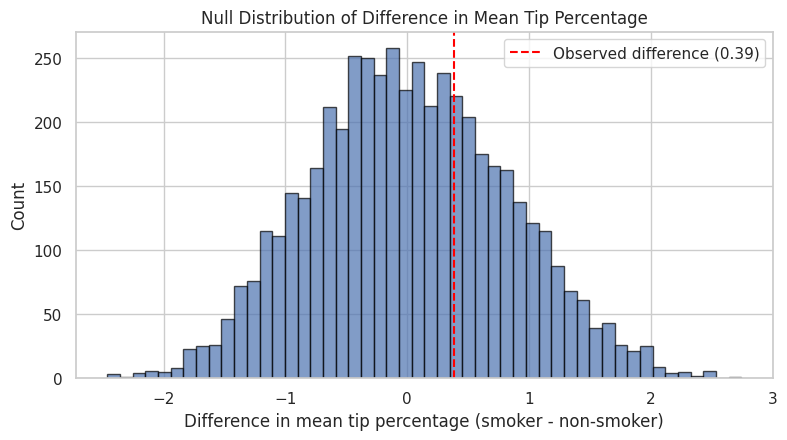

In [13]:
# Goal 3b · Figure · 1 pt
# TODO: plot the null distribution with the observed value marked

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(null_diffs, bins=50, edgecolor="black", alpha=0.7)
ax.axvline(observed, color="red", linestyle="--", label=f"Observed difference ({round(observed, 2)})")
ax.set_xlabel("Difference in mean tip percentage (smoker - non-smoker)")
ax.set_ylabel("Count")
ax.set_title("Null Distribution of Difference in Mean Tip Percentage")
ax.legend()
plt.show()

**Q2 · 0.75 pt.** Copy the numbers from **your own output above**. Write the conclusion in two sentences that a restaurant manager would understand. Do not use the words *significant*, *null* or *reject*.

A2: In our records, tables with smokers tipped an average of 16.32% (93 tables) and tables without smokers tipped 15.93% (151 tables), which is a tiny difference of only 0.39 percentage points. Because about 65% of random shuffles gave a difference at least this big (p-value = 0.6464), this small gap can easily happen by pure luck, meaning there is no real evidence that smoking habits change how much people tip.

**Q3 · 0.5 pt.** A classmate writes: *"the p-value is high, so we proved smokers and non-smokers tip the same."* Two things are wrong with that sentence. Name both.

A3:

You cannot "prove" a claim: In statistics, we never prove that two groups are identical. A high p-value only means that our data does not provide enough evidence of a difference; lack of evidence is not proof of no difference.

They do not tip the exact same: The two groups did not have the exact same tip percentage in our data (smokers tipped 16.32% and non-smokers tipped 15.93%, a difference of 0.39 percentage points). The high p-value simply means that this small difference could easily occur by random chance, not that the difference is zero.

## 4. The bootstrap

A different question: not *is there a difference*, but *how precisely do we know the mean tip percentage at all?* Resample the data with replacement, recompute the mean, repeat. The middle 95% of those means is the confidence interval.

> **Goal 4a · 1.25 pt.** The first lines of the cell are **ready-made** (down to `boot_means = np.empty(n_boot)`): they store the 244 tip percentages as `all_tips` and make an empty array `boot_means` with 5,000 places. This cell has no seed of its own: it goes on with the `rng` of Part 3.
> Fill in the loop. **Inside** the loop, in place of `...`, write two lines:
> 1. draw a bootstrap sample with `rng.choice(all_tips, size=len(all_tips), replace=True)` and store it as `sample`;
> 2. put the mean of `sample` in place `i` of `boot_means`.
>
> After the loop, find the 95% interval — the 2.5th and the 97.5th percentiles of `boot_means` — and store its two ends as **`lo`** and **`hi`**. Print the mean of `all_tips`, `lo`, `hi` and the width of the interval (`hi - lo`), each rounded to 2 decimals.

In [14]:
# Goal 4a · 1.25 pt
n_boot = 5000
all_tips = tips["tip_pct"].values
boot_means = np.empty(n_boot)
for i in range(n_boot):
  sample = rng.choice(all_tips, size=len(all_tips), replace=True)
  boot_means[i] = sample.mean()
    # TODO: resample WITH replacement, same size as the original,
    #       and record the mean

# TODO: the 95% interval is the 2.5th and 97.5th percentiles
lo, hi = np.percentile(boot_means, [2.5, 97.5])
print("Mean tip %:", round(all_tips.mean(), 2))
print("Lower bound (lo):", round(lo, 2))
print("Upper bound (hi):", round(hi, 2))
print("Interval width:", round(hi - lo, 2))

Mean tip %: 16.08
Lower bound (lo): 15.35
Upper bound (hi): 16.91
Interval width: 1.57


> **Goal 4b · Figure · 1 pt.** Plot the **bootstrap distribution**: a histogram of the 5,000 values in `boot_means`, with 50 bars. Mark the two ends of the interval with **two vertical lines**, at `lo` and at `hi`. Give the figure an x label, a y label and a title.

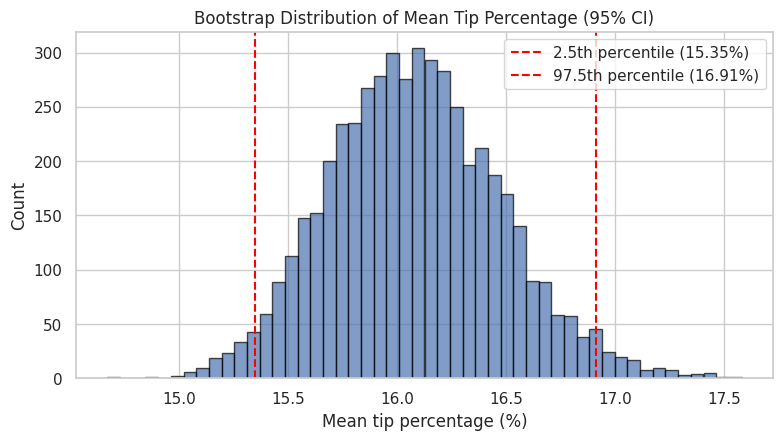

In [15]:
# Goal 4b · Figure · 1 pt
# TODO: plot the bootstrap distribution with the interval bounds marked

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(boot_means, bins=50, edgecolor="black", alpha=0.7)
ax.axvline(lo, color="red", linestyle="--", label=f"2.5th percentile ({round(lo, 2)}%)")
ax.axvline(hi, color="red", linestyle="--", label=f"97.5th percentile ({round(hi, 2)}%)")
ax.set_xlabel("Mean tip percentage (%)")
ax.set_ylabel("Count")
ax.set_title("Bootstrap Distribution of Mean Tip Percentage (95% CI)")
ax.legend()
plt.show()

**Q4 · 0.5 pt.** Copy the numbers from **your own output above**. The interval is about one and a half percentage point wide. What would you have to do to halve that width? Use the rule you found in Lab 6.

A4: From our output above, the sample mean is 16.08%, the 95% bootstrap interval is [15.35%, 16.91%], and its width is 1.57 percentage points.

According to the square root rule from Lab 6, the width of the confidence interval is inversely proportional to the square root of the sample size. To cut the interval width in half (divide by 2), we must increase the sample size by a factor of 2² = 4. Since the current sample has n = 244 tables, we would need to collect data from 244 * 4 = 976 tables to halve the width.

**Q5 · 0.75 pt.** Which of these is a correct reading of your interval, and why are the others wrong?

a) 95% of tables tip within this range.
b) There is a 95% chance the true mean is in this interval.
c) If we repeated the whole study many times, about 95% of the intervals built this way would contain the true mean.

A5:

Why (c) is correct: A 95% confidence interval is about the reliability of the method over repeated sampling. If we repeated the entire data collection process many times and calculated a 95% bootstrap interval from each sample, about 95% of those intervals would contain the true population mean.

Why (a) is wrong: The interval estimates the average tip percentage across all tables, not the tip of individual tables. Individual tables vary widely (many tip 10%, 20%, or 25%), so much less than 95% of individual tables fall between 15.35% and 16.91%.

Why (b) is wrong: In classical statistics, the true population mean is a fixed unknown number, not a random variable. Once this specific interval [15.35%, 16.91%] is calculated, the true mean is either inside it or outside it (the probability is either 1 or 0). The 95% probability applies to the long-run procedure across many samples, not to this one fixed interval.

## 5. On your own

Repeat the permutation test for a different question in the same dataset: **do weekend tables tip a different percentage than weekday tables?** Report the observed difference, the p-value, and your conclusion in plain language.

> **Goal 5 · 1.25 pt.** Write your own permutation test in the cell below. **Weekend** tables are the tables with `day` equal to `"Sat"` or `"Sun"`; **weekday** tables are the tables with `day` equal to `"Thur"` or `"Fri"` (the table has no other days). Follow the same steps as in Parts 2 and 3:
> 1. store the `tip_pct` values of the two groups as two arrays, and the observed difference: weekend **minus** weekday;
> 2. start the random part with the line `rng = np.random.default_rng(5)`, so that your numbers can be checked; then shuffle 5,000 times in a loop, as in Part 3;
> 3. compute the two-sided p-value.
>
> Print the number of tables and the mean `tip_pct` of both groups, the observed difference and the p-value. Then write your **conclusion in plain language** in the text cell under the code (the same rule as in Q2: do not use *significant*, *null* or *reject*).

In [16]:
# Goal 5 · 1.25 pt
# TODO: your own permutation test for the weekend/weekday question
weekend_mask = tips["day"].isin(["Sat", "Sun"])
weekend = tips[weekend_mask]["tip_pct"].values
weekday = tips[~weekend_mask]["tip_pct"].values
print("Weekend tables:", len(weekend), "| mean tip %:", round(weekend.mean(), 2))
print("Weekday tables:", len(weekday), "| mean tip %:", round(weekday.mean(), 2))
observed_day = weekend.mean() - weekday.mean()
print("Observed difference (weekend - weekday):", round(observed_day, 2))
rng = np.random.default_rng(5)
pooled_day = np.concatenate([weekend, weekday])
n_weekend = len(weekend)
n_reps = 5000
null_diffs_day = np.empty(n_reps)
for i in range(n_reps):
    shuffled_day = rng.permutation(pooled_day)
    null_diffs_day[i] = shuffled_day[:n_weekend].mean() - shuffled_day[n_weekend:].mean()
p_day = np.mean(np.abs(null_diffs_day) >= abs(observed_day))
print("p-value:", round(p_day, 4))

Weekend tables: 163 | mean tip %: 15.96
Weekday tables: 81 | mean tip %: 16.33
Observed difference (weekend - weekday): -0.37
p-value: 0.6516


**Goal 5 — your conclusion in plain language** *(part of Goal 5)*

In our dataset, weekend tables tipped an average of 15.96% (163 tables) while weekday tables tipped an average of 16.33% (81 tables), showing a tiny difference of -0.37 percentage points. In our simulation of 5,000 shuffles, about 65% of random shuffles produced a difference at least this large (p-value = 0.6516). Because such a small gap occurs very frequently by random luck, there is no evidence that customers tip differently on weekends compared to weekdays.

## 6. Push to GitHub

1. You created a repository named `dsa107-labs` in Lab 1. Use the same one.
2. In Colab: **File → Save a copy in GitHub**, and choose that repository.
3. Paste the resulting link in the line below.

**Repository link:** https://github.com/besim974/DSA107

---

## Submission checklist

- [ ] Every cell runs top to bottom without error (Runtime → Restart and run all)
- [ ] No `...` is left in a loop that you filled in, and your numbers are close to the **Check:** lines
- [ ] Both figures (Goals 3b and 4b) have an x label, a y label, a title and their marked lines
- [ ] Every written answer is filled in — a plot with no reading of it scores zero on interpretation
- [ ] Notebook saved as `Lab08_Firstname_Lastname.ipynb` — open it once more before you upload it, to be sure it is the **filled** notebook and not the empty starter
- [ ] Report exported as `Lab08_Firstname_Lastname.pdf`
- [ ] If you used an AI assistant, the log is attached as described in the course AI policy

Submit both files through MS Teams.